# 02 · Pandas DataFrames & Data Cleaning — deep dive

> **Course:** Data Analytics Laboratory · IIIT Dharwad · companion to [`../02-Pandas-DataFrames-and-Data-Cleaning.md`](../02-Pandas-DataFrames-and-Data-Cleaning.md)
>
> Every number quoted in the note is produced here. Run top to bottom (pandas ≥ 2.0; tested on pandas 3.0).

| Part | Topic |
|:-:|:--|
| A | Creating DataFrames & Series |
| B | The manual's examples, corrected (iris) |
| C | Inspecting a messy dataset |
| D | Missing values & NaN semantics |
| E | Text standardisation |
| F | Duplicates: rows vs keys |
| G | Invalid values → NaN |
| H | Imputation: mean vs median vs mode |
| I | Validation with `assert` |
| J | Filtering, sorting, derived columns |
| K | `groupby`, `agg`, `pivot_table`, plotting |
| L | Export & round-trip |
| M | Pitfalls: chained assignment, `inplace`, `and` vs `&` |
| N | Practice-problem solutions |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 120)
print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 3.0.3 | numpy 2.4.6


## Part A — Creating DataFrames & Series

A **DataFrame** is a table: rows share an **index**, every column is a **Series** with one dtype.

In [2]:
# 1) from a dict of lists (column-wise) — the manual's example
data = {"Name": ["Alice", "Bob", "Charlie"], "Age": [25, 30, 22]}
people = pd.DataFrame(data)
print(people, "\n")

# 2) from a list of dicts (row-wise) — missing keys become NaN
rows = [{"Name": "Dev", "Age": 28}, {"Name": "Ela"}]
print(pd.DataFrame(rows), "\n")

# 3) from a NumPy array + column names
arr = np.arange(6).reshape(3, 2)
print(pd.DataFrame(arr, columns=["x", "y"]), "\n")

# A single column is a Series
print(type(people["Age"]), people["Age"].dtype)
print(type(people[["Age"]]))           # double brackets -> DataFrame

      Name  Age
0    Alice   25
1      Bob   30
2  Charlie   22 

  Name   Age
0  Dev  28.0
1  Ela   NaN 

   x  y
0  0  1
1  2  3
2  4  5 

<class 'pandas.Series'> int64
<class 'pandas.DataFrame'>


In [3]:
# Adding / modifying columns (manual example)
people["Salary"] = [50000, 60000, 45000]
people["Salary_k"] = people["Salary"] / 1000        # vectorised, no loop
print(people)
print(people.dtypes)

      Name  Age  Salary  Salary_k
0    Alice   25   50000      50.0
1      Bob   30   60000      60.0
2  Charlie   22   45000      45.0
Name            str
Age           int64
Salary        int64
Salary_k    float64
dtype: object


## Part B — The manual's examples, corrected (iris)

The manual writes `from sklearn.dataset import load_iris` and `df.petal width`. Correct versions below.
The `Salaries.csv` URL in the manual currently returns **HTTP 404**, so it is wrapped in `try/except`.

In [4]:
from sklearn.datasets import load_iris          # 'datasets', plural

iris = load_iris(as_frame=True).frame           # a ready DataFrame
iris.columns = ["sepal_length", "sepal_width", "petal_length", "petal_width", "target"]
iris["species"] = iris["target"].map({0: "setosa", 1: "versicolor", 2: "virginica"})
print(iris.shape)
print(iris.head())

(150, 6)
   sepal_length  sepal_width  petal_length  petal_width  target species
0           5.1          3.5           1.4          0.2       0  setosa
1           4.9          3.0           1.4          0.2       0  setosa
2           4.7          3.2           1.3          0.2       0  setosa
3           4.6          3.1           1.5          0.2       0  setosa
4           5.0          3.6           1.4          0.2       0  setosa


In [5]:
print(iris["petal_width"][1:4], "\n")          # positions 1,2,3 (stop excluded)
print(iris["petal_width"][4], "\n")            # label 4 (here label == position)
print(iris.loc[:, "petal_length":"petal_width"].head(3), "\n")   # label slice: BOTH ends included
print(iris.iloc[0:3, 2:4])                      # position slice: stop excluded

1    0.2
2    0.2
3    0.2
Name: petal_width, dtype: float64 

0.2 

   petal_length  petal_width
0           1.4          0.2
1           1.4          0.2
2           1.3          0.2 

   petal_length  petal_width
0           1.4          0.2
1           1.4          0.2
2           1.3          0.2


In [6]:
# Filtering. Manual: df.petal width > 3.0  -> max petal width is 2.5, so nothing matches.
print("max petal_width:", iris["petal_width"].max())
print("rows with petal_width > 3.0:", (iris["petal_width"] > 3.0).sum())

wide = iris[(iris["petal_width"] >= 1.5) & (iris["petal_length"] < 5.0)]  # both conditions
print("petal_width >= 1.5 AND petal_length < 5.0:", len(wide))
print(wide["species"].value_counts())

max petal_width: 2.5
rows with petal_width > 3.0: 0
petal_width >= 1.5 AND petal_length < 5.0: 19
species
versicolor    13
virginica      6
Name: count, dtype: int64


In [7]:
# groupby + mean (manual's grouping example, on iris)
print(iris.groupby("species")["petal_length"].mean().round(3))

species
setosa        1.462
versicolor    4.260
virginica     5.552
Name: petal_length, dtype: float64


In [8]:
# The manual's remote CSV
try:
    sal = pd.read_csv("http://rcs.bu.edu/examples/python/data_analysis/Salaries.csv")
    print(sal.shape)
except Exception as e:
    print("Could not load Salaries.csv ->", type(e).__name__, e)

Could not load Salaries.csv -> HTTPError HTTP Error 404: Not Found


## Part C — Inspecting a messy dataset

Our running example: 14 online-shop orders with typical defects (missing values, an impossible rating, an exact duplicate row, a re-used order ID, inconsistent city spellings).

In [9]:
data = {
    "Order_ID":   [201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 203, 207, 213, 214],
    "Customer":   ["Anil", "bhavya ", " Chetan", "Deepa", "Esha", "Farhan", "Gita", "Hari",
                   "Isha", "Jay", " Chetan", "Kavya", "Lokesh", "Mani"],
    "City":       ["Dharwad", "Hubli", "dharwad", "Belagavi", "Hubli", "Dharwad ", "Belagavi",
                   "hubli", "Dharwad", "Belagavi", "dharwad", "Hubli", "Dharwad", "HUBLI"],
    "Category":   ["Books", "Electronics", "Books", "Grocery", "Electronics", "Grocery", "Books",
                   "Electronics", "Grocery", "Books", "Books", "Grocery", "Electronics", "Books"],
    "Quantity":   [2, 1, 3, np.nan, 1, 5, 2, 1, 4, np.nan, 3, 6, 1, 2],
    "Unit_Price": [350, 15999, 250, 120, 899, 60, np.nan, 45999, 80, 499, 250, 75, 2499, np.nan],
    "Rating":     [5, 4, np.nan, 3, 7, 4, 5, np.nan, 2, 4, np.nan, 3, 5, 4],   # valid range 1-5
}
raw = pd.DataFrame(data)
df = raw.copy()          # keep the raw data untouched
df

,Order_ID,Customer,City,Category,Quantity,Unit_Price,Rating
0,201,Anil,Dharwad,Books,2.0,350.0,5.0
1,202,bhavya,Hubli,Electronics,1.0,15999.0,4.0
2,203,Chetan,dharwad,Books,3.0,250.0,NaN
3,204,Deepa,Belagavi,Grocery,NaN,120.0,3.0
4,205,Esha,Hubli,Electronics,1.0,899.0,7.0
5,206,Farhan,Dharwad,Grocery,5.0,60.0,4.0
6,207,Gita,Belagavi,Books,2.0,NaN,5.0
7,208,Hari,hubli,Electronics,1.0,45999.0,NaN
8,209,Isha,Dharwad,Grocery,4.0,80.0,2.0
9,210,Jay,Belagavi,Books,NaN,499.0,4.0


In [10]:
print(df.head(), "\n")
print(df.tail(), "\n")
print("shape:", df.shape, "| rows:", df.shape[0], "| cols:", df.shape[1])
print("columns:", df.columns.tolist())

   Order_ID Customer      City     Category  Quantity  Unit_Price  Rating
0       201     Anil   Dharwad        Books       2.0       350.0     5.0
1       202  bhavya      Hubli  Electronics       1.0     15999.0     4.0
2       203   Chetan   dharwad        Books       3.0       250.0     NaN
3       204    Deepa  Belagavi      Grocery       NaN       120.0     3.0
4       205     Esha     Hubli  Electronics       1.0       899.0     7.0 

    Order_ID Customer      City     Category  Quantity  Unit_Price  Rating
9        210      Jay  Belagavi        Books       NaN       499.0     4.0
10       203   Chetan   dharwad        Books       3.0       250.0     NaN
11       207    Kavya     Hubli      Grocery       6.0        75.0     3.0
12       213   Lokesh   Dharwad  Electronics       1.0      2499.0     5.0
13       214     Mani     HUBLI        Books       2.0         NaN     4.0 

shape: (14, 7) | rows: 14 | cols: 7
columns: ['Order_ID', 'Customer', 'City', 'Category', 'Quantity', 

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14 entries, 0 to 13
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Order_ID    14 non-null     int64  
 1   Customer    14 non-null     str    
 2   City        14 non-null     str    
 3   Category    14 non-null     str    
 4   Quantity    12 non-null     float64
 5   Unit_Price  12 non-null     float64
 6   Rating      11 non-null     float64
dtypes: float64(3), int64(1), str(3)
memory usage: 1.2 KB


In [12]:
df.describe().round(2)

,Order_ID,Quantity,Unit_Price,Rating
count,14.00,12.00,12.00,11.00
mean,206.57,2.58,5590.00,4.18
std,3.96,1.68,13499.09,1.33
min,201.00,1.00,60.00,2.00
25%,203.25,1.00,110.00,3.50
50%,206.50,2.00,300.00,4.00
75%,208.75,3.25,1299.00,5.00
max,214.00,6.00,45999.00,7.00


In [13]:
df.describe(exclude="number")      # count / unique / top / freq for text columns

,Customer,City,Category
count,14,14,14
unique,13,7,3
top,Chetan,Dharwad,Books
freq,2,3,6


In [14]:
num_cols = df.select_dtypes(include="number").columns.tolist()
cat_cols = df.select_dtypes(exclude="number").columns.tolist()
print("numeric    :", num_cols)
print("categorical:", cat_cols)
print("\nOrder_ID is numeric by dtype but is an IDENTIFIER: never average it.")

numeric    : ['Order_ID', 'Quantity', 'Unit_Price', 'Rating']
categorical: ['Customer', 'City', 'Category']

Order_ID is numeric by dtype but is an IDENTIFIER: never average it.


In [15]:
print(df["City"].value_counts())    # 7 'cities' that are really 3
print("\nunique repr:", [repr(c) for c in df["City"].unique()])

City
Dharwad     3
Hubli       3
Belagavi    3
dharwad     2
Dharwad     1
hubli       1
HUBLI       1
Name: count, dtype: int64

unique repr: ["'Dharwad'", "'Hubli'", "'dharwad'", "'Belagavi'", "'Dharwad '", "'hubli'", "'HUBLI'"]


## Part D — Missing values & NaN semantics

In [16]:
missing = pd.DataFrame({
    "missing": df.isna().sum(),
    "percent": (df.isna().mean() * 100).round(2),
})
missing

,missing,percent
Order_ID,0,0.00
Customer,0,0.00
City,0,0.00
Category,0,0.00
Quantity,2,14.29
Unit_Price,2,14.29
Rating,3,21.43


In [17]:
print("total missing cells:", df.isna().sum().sum(), "of", df.size)
print("rows with >= 1 missing value:")
df[df.isna().any(axis=1)]

total missing cells: 7 of 98
rows with >= 1 missing value:


,Order_ID,Customer,City,Category,Quantity,Unit_Price,Rating
2,203,Chetan,dharwad,Books,3.0,250.0,NaN
3,204,Deepa,Belagavi,Grocery,NaN,120.0,3.0
6,207,Gita,Belagavi,Books,2.0,NaN,5.0
7,208,Hari,hubli,Electronics,1.0,45999.0,NaN
9,210,Jay,Belagavi,Books,NaN,499.0,4.0
10,203,Chetan,dharwad,Books,3.0,250.0,NaN
13,214,Mani,HUBLI,Books,2.0,NaN,4.0


In [18]:
# NaN semantics
print("np.nan == np.nan :", np.nan == np.nan)
print("pd.isna(np.nan)  :", pd.isna(np.nan))
s = pd.Series([1.0, np.nan, 3.0])
print("sum  :", s.sum(), "| mean:", s.mean(), "| count:", s.count(), "| len:", len(s))
print("mean(skipna=False):", s.mean(skipna=False))
print("s > 0 :", (s > 0).tolist(), "  <- NaN compares as False")
print("int column with NaN becomes float:", pd.Series([1, None, 3]).dtype)

np.nan == np.nan : False
pd.isna(np.nan)  : True
sum  : 4.0 | mean: 2.0 | count: 2 | len: 3
mean(skipna=False): nan
s > 0 : [True, False, True]   <- NaN compares as False
int column with NaN becomes float: float64


In [19]:
# dropna options
print("dropna()            ->", df.dropna().shape)
print("dropna(subset=['Unit_Price']) ->", df.dropna(subset=["Unit_Price"]).shape)
print("dropna(thresh=6)    ->", df.dropna(thresh=6).shape, "(keep rows with >= 6 non-null values)")

dropna()            -> (7, 7)
dropna(subset=['Unit_Price']) -> (12, 7)
dropna(thresh=6)    -> (14, 7) (keep rows with >= 6 non-null values)


## Part E — Text standardisation (clean text before looking for duplicates)

In [20]:
for col in ["Customer", "City", "Category"]:
    df[col] = df[col].str.strip().str.title()

print(df["City"].value_counts())
print("\nCustomers:", df["Customer"].tolist())

City
Dharwad     6
Hubli       5
Belagavi    3
Name: count, dtype: int64

Customers: ['Anil', 'Bhavya', 'Chetan', 'Deepa', 'Esha', 'Farhan', 'Gita', 'Hari', 'Isha', 'Jay', 'Chetan', 'Kavya', 'Lokesh', 'Mani']


In [21]:
# Other useful .str methods
s = pd.Series(["  new   delhi ", "MUMBAI", "bengaluru-urban"])
print(s.str.strip().tolist())
print(s.str.split().str.join(" ").tolist(), " <- collapses inner spaces")
print(s.str.replace("-", " ").str.title().tolist())
print(s.str.contains("bai", case=False).tolist())

['new   delhi', 'MUMBAI', 'bengaluru-urban']
['new delhi', 'MUMBAI', 'bengaluru-urban']  <- collapses inner spaces
['  New   Delhi ', 'Mumbai', 'Bengaluru Urban']
[False, True, False]


## Part F — Duplicates: rows vs keys (remove before computing statistics)

In [22]:
print("exact duplicate rows:", df.duplicated().sum())
print(df[df.duplicated(keep=False)], "\n")

print("duplicated Order_IDs:", df["Order_ID"].duplicated().sum())
print(df[df["Order_ID"].duplicated(keep=False)].sort_values("Order_ID"))

exact duplicate rows: 1
    Order_ID Customer     City Category  Quantity  Unit_Price  Rating
2        203   Chetan  Dharwad    Books       3.0       250.0     NaN
10       203   Chetan  Dharwad    Books       3.0       250.0     NaN 

duplicated Order_IDs: 2


    Order_ID Customer      City Category  Quantity  Unit_Price  Rating
2        203   Chetan   Dharwad    Books       3.0       250.0     NaN
10       203   Chetan   Dharwad    Books       3.0       250.0     NaN
6        207     Gita  Belagavi    Books       2.0         NaN     5.0
11       207    Kavya     Hubli  Grocery       6.0        75.0     3.0


In [23]:
# keep options
print("keep='first':", df.duplicated(keep="first").tolist().count(True),
      "| keep='last':", df.duplicated(keep="last").tolist().count(True),
      "| keep=False:", df.duplicated(keep=False).tolist().count(True))

keep='first': 1 | keep='last': 1 | keep=False: 2


In [24]:
# Order 203 appears twice and the rows are identical -> safe to drop the copy.
# Order 207 appears twice with DIFFERENT customer/category -> two real orders sharing an ID: flag, don't delete.
df = df.drop_duplicates().reset_index(drop=True)
print("shape after dropping exact duplicates:", df.shape)
df["ID_conflict"] = df["Order_ID"].duplicated(keep=False)
df[df["ID_conflict"]]

shape after dropping exact duplicates: (13, 7)


,Order_ID,Customer,City,Category,Quantity,Unit_Price,Rating,ID_conflict
6,207,Gita,Belagavi,Books,2.0,NaN,5.0,True
10,207,Kavya,Hubli,Grocery,6.0,75.0,3.0,True


In [25]:
# Why clean text BEFORE checking duplicates: whitespace hides duplicates
t = pd.DataFrame({"name": ["Asha", "Asha "], "city": ["Pune", "pune"]})
print("before cleaning:", t.duplicated().sum())
t = t.apply(lambda c: c.str.strip().str.title())
print("after cleaning :", t.duplicated().sum())

before cleaning: 0


after cleaning : 1


## Part G — Invalid values → NaN

Rating must be 1–5. A 7 is **not data**, it is an error. Mark it missing **first**; the median used for imputation (Part H) is then computed from valid values only.

In [26]:
invalid = ~df["Rating"].between(1, 5) & df["Rating"].notna()
print("invalid ratings:\n", df.loc[invalid, ["Order_ID", "Rating"]])

print("\nmedian INCLUDING the 7:", df["Rating"].median(), "| mean including 7:", round(df["Rating"].mean(), 4))
df.loc[invalid, "Rating"] = np.nan
print("median of VALID ratings:", df["Rating"].median(), "| mean of valid:", round(df["Rating"].mean(), 4))
print("missing ratings now:", df["Rating"].isna().sum())

invalid ratings:
 

   Order_ID  Rating
4       205     7.0

median INCLUDING the 7: 4.0 | mean including 7: 4.1818
median of VALID ratings: 4.0 | mean of valid: 3.9
missing ratings now: 3


## Part H — Imputation: mean vs median vs mode

In [27]:
price = df["Unit_Price"]
print("Unit_Price mean  :", round(price.mean(), 2))
print("Unit_Price median:", price.median())
print("skewness         :", round(price.skew(), 3))
print("without the two big items (15999, 45999): mean =",
      round(price[price < 10000].mean(), 2), "median =", price[price < 10000].median())

Unit_Price mean  : 6075.45
Unit_Price median: 350.0
skewness         : 2.778
without the two big items (15999, 45999): mean = 536.89 median = 250.0


In [28]:
q = df["Quantity"]
print("Quantity mean:", round(q.mean(), 4), "| median:", q.median(), "| mode:", q.mode().tolist())

Quantity mean: 2.5455 | median: 2.0 | mode: [1.0]


In [29]:
# Category-wise median is smarter for price: a missing Books price should not be filled with an Electronics-influenced value
print(df.groupby("Category")["Unit_Price"].median())
cat_median = df.groupby("Category")["Unit_Price"].transform("median")
print("\nrows with missing price and the value they would get:")
print(pd.DataFrame({"Category": df["Category"], "Unit_Price": price, "fill": cat_median})[price.isna()])

Category
Books           350.0
Electronics    9249.0
Grocery          77.5
Name: Unit_Price, dtype: float64

rows with missing price and the value they would get:
   Category  Unit_Price   fill
6     Books         NaN  350.0
12    Books         NaN  350.0


In [30]:
before = raw.isna().sum()          # missing counts in the raw data

df["Quantity"]   = df["Quantity"].fillna(df["Quantity"].median())
df["Unit_Price"] = df["Unit_Price"].fillna(cat_median)
df["Rating"]     = df["Rating"].fillna(df["Rating"].median())   # median of VALID ratings (7 already removed)
df[["Quantity", "Unit_Price", "Rating"]]

,Quantity,Unit_Price,Rating
0,2.0,350.0,5.0
1,1.0,15999.0,4.0
2,3.0,250.0,4.0
3,2.0,120.0,3.0
4,1.0,899.0,4.0
5,5.0,60.0,4.0
6,2.0,350.0,5.0
7,1.0,45999.0,4.0
8,4.0,80.0,2.0
9,2.0,499.0,4.0


In [31]:
after = df[before.index].isna().sum()
# Rating: raw had 3 NaN; dropping the duplicate row removed one; Part G turned the 7 into NaN -> 3 values imputed
pd.DataFrame({"before": before, "after": after})

,before,after
Order_ID,0,0
Customer,0,0
City,0,0
Category,0,0
Quantity,2,0
Unit_Price,2,0
Rating,3,0


## Part I — Validation with `assert`

In [32]:
assert df["Rating"].between(1, 5).all(), "rating out of range"
assert df[["Quantity", "Unit_Price", "Rating"]].notna().all().all(), "missing values remain"
assert (df["Quantity"] > 0).all()
assert not df.duplicated().any()
print("all checks passed; min/max rating:", df["Rating"].min(), df["Rating"].max())

all checks passed; min/max rating: 2.0 5.0


## Part J — Filtering, sorting, derived columns

In [33]:
df["Total"] = df["Quantity"] * df["Unit_Price"]

print(df[df["Total"] >= 1000][["Order_ID", "Customer", "Total"]], "\n")
print(df[df["City"].isin(["Hubli", "Belagavi"]) & (df["Rating"] < 4)][["Order_ID", "City", "Rating"]], "\n")
print(df.query("Category == 'Books' and Quantity >= 3")[["Order_ID", "Quantity"]])

    Order_ID Customer    Total
1        202   Bhavya  15999.0
7        208     Hari  45999.0
11       213   Lokesh   2499.0 



    Order_ID      City  Rating
3        204  Belagavi     3.0
10       207     Hubli     3.0 

   Order_ID  Quantity
2       203       3.0


In [34]:
df.sort_values("Total", ascending=False)[["Order_ID", "Customer", "Category", "Total"]].head(5)

,Order_ID,Customer,Category,Total
7,208,Hari,Electronics,45999.0
1,202,Bhavya,Electronics,15999.0
11,213,Lokesh,Electronics,2499.0
9,210,Jay,Books,998.0
4,205,Esha,Electronics,899.0


In [35]:
# multi-key sort: City A->Z, then Total high->low
df.sort_values(["City", "Total"], ascending=[True, False])[["City", "Order_ID", "Total"]]

,City,Order_ID,Total
9,Belagavi,210,998.0
6,Belagavi,207,700.0
3,Belagavi,204,240.0
11,Dharwad,213,2499.0
2,Dharwad,203,750.0
0,Dharwad,201,700.0
8,Dharwad,209,320.0
5,Dharwad,206,300.0
7,Hubli,208,45999.0
1,Hubli,202,15999.0


In [36]:
# Three ways to make a category column
conditions = [df["Total"] >= 5000, df["Total"] >= 500]
choices    = ["High", "Medium"]
df["Value_Band"] = np.select(conditions, choices, default="Low")       # first true condition wins

df["Value_Band_cut"] = pd.cut(df["Total"], bins=[0, 500, 5000, np.inf],
                              labels=["Low", "Medium", "High"], right=False)   # [0,500) [500,5000) [5000,inf)

df["Happy"] = np.where(df["Rating"] >= 4, "Yes", "No")

print((df["Value_Band"] == df["Value_Band_cut"].astype(str)).all())
df[["Order_ID", "Total", "Value_Band", "Value_Band_cut", "Rating", "Happy"]]

True


,Order_ID,Total,Value_Band,Value_Band_cut,Rating,Happy
0,201,700.0,Medium,Medium,5.0,Yes
1,202,15999.0,High,High,4.0,Yes
2,203,750.0,Medium,Medium,4.0,Yes
3,204,240.0,Low,Low,3.0,No
4,205,899.0,Medium,Medium,4.0,Yes
5,206,300.0,Low,Low,4.0,Yes
6,207,700.0,Medium,Medium,5.0,Yes
7,208,45999.0,High,High,4.0,Yes
8,209,320.0,Low,Low,2.0,No
9,210,998.0,Medium,Medium,4.0,Yes


In [37]:
# right=True (the default) puts a value equal to an edge into the LOWER bin
edge = pd.Series([500, 5000])
print("right=False:", pd.cut(edge, [0, 500, 5000, np.inf], labels=["Low", "Medium", "High"], right=False).tolist())
print("right=True :", pd.cut(edge, [0, 500, 5000, np.inf], labels=["Low", "Medium", "High"]).tolist())

right=False: ['Medium', 'High']
right=True : ['Low', 'Medium']


## Part K — `groupby`, `agg`, `pivot_table`, plotting

In [38]:
summary = df.groupby("Category").agg(
    orders=("Order_ID", "count"),
    units=("Quantity", "sum"),
    revenue=("Total", "sum"),
    avg_rating=("Rating", "mean"),
).round(2).sort_values("revenue", ascending=False)
summary

,orders,units,revenue,avg_rating
Category,,,,
Electronics,4,4.0,65396.0,4.25
Books,5,11.0,3848.0,4.40
Grocery,4,17.0,1310.0,3.00


In [39]:
pd.pivot_table(df, index="City", columns="Category", values="Total", aggfunc="sum", fill_value=0)

Category,Books,Electronics,Grocery
City,,,
Belagavi,1698.0,0.0,240.0
Dharwad,1450.0,2499.0,620.0
Hubli,700.0,62897.0,450.0


In [40]:
pd.crosstab(df["City"], df["Value_Band"])

Value_Band,High,Low,Medium
City,,,
Belagavi,0,1,2
Dharwad,0,2,3
Hubli,2,1,2


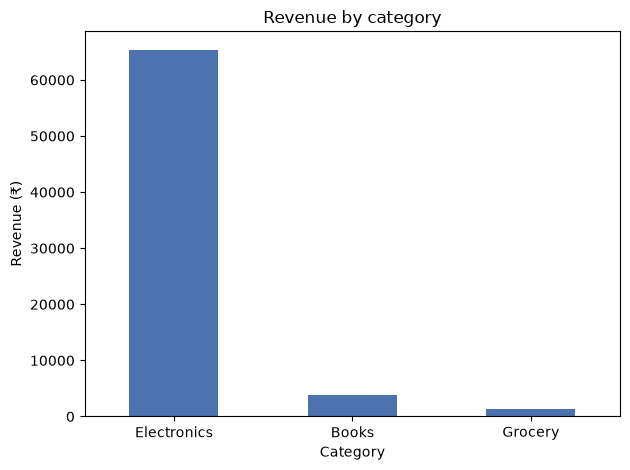

In [41]:
ax = summary["revenue"].plot(kind="bar", color="#4C72B0", rot=0, title="Revenue by category")
ax.set_ylabel("Revenue (₹)")
plt.tight_layout()
plt.show()

## Part L — Export & round-trip

In [42]:
import os, tempfile
out = os.path.join(tempfile.gettempdir(), "orders_clean.csv")
clean = df.drop(columns=["Value_Band_cut"])
clean.to_csv(out, index=False)          # index=False: don't write 0..n-1 as an extra column
back = pd.read_csv(out)
pd.testing.assert_frame_equal(back, clean, check_dtype=False)   # raises if anything differs
print("round-trip OK:", back.shape)
print(back.dtypes)

round-trip OK: (13, 11)
Order_ID         int64
Customer           str
City               str
Category           str
Quantity       float64
Unit_Price     float64
Rating         float64
ID_conflict       bool
Total          float64
Value_Band         str
Happy              str
dtype: object


## Part M — Pitfalls (pandas 2 / 3)

In [43]:
import warnings
t = pd.DataFrame({"a": [1, 2, 3], "b": [np.nan, 5.0, 6.0]})

with warnings.catch_warnings(record=True) as w:
    warnings.simplefilter("always")
    t[t["a"] > 1]["b"] = 0                 # chained assignment: never updates t
    t["b"].fillna(0, inplace=True)         # inplace on a column: never updates t
print("t unchanged:\n", t)
print("warnings raised:", [type(x.message).__name__ for x in w])

t.loc[t["a"] > 1, "b"] = 0                 # correct: one .loc call
t["b"] = t["b"].fillna(-1)                 # correct: assign the result back
print("\nt fixed:\n", t)

t unchanged:
    a    b
0  1  NaN
1  2  5.0
2  3  6.0
warnings raised: ['ChainedAssignmentError', 'ChainedAssignmentError']

t fixed:
    a    b
0  1 -1.0
1  2  0.0
2  3  0.0


In [44]:
try:
    t[(t["a"] > 1) and (t["b"] > 0)]
except ValueError as e:
    print("ValueError:", str(e)[:70], "...")
print(t[(t["a"] > 1) & (t["b"] >= 0)])
try:
    t[t["a"] > 1 & t["b"] >= 0]           # no parentheses: & binds tighter than >
except Exception as e:
    print(type(e).__name__, "-> always parenthesise each condition")

ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.ite ...
   a    b
1  2  0.0
2  3  0.0
TypeError -> always parenthesise each condition


## Part N — Practice-problem solutions

In [45]:
# P1: percentage of missing values in the RAW data, sorted
print((raw.isna().mean() * 100).round(2).sort_values(ascending=False))

Rating        21.43
Quantity      14.29
Unit_Price    14.29
City           0.00
Customer       0.00
Order_ID       0.00
Category       0.00
dtype: float64


In [46]:
# P2: mean vs median of [3, 4, 4, 5, 100]
x = pd.Series([3, 4, 4, 5, 100])
print("mean", x.mean(), "| median", x.median(), "| mode", x.mode().tolist())

mean 23.2 | median 4.0 | mode [4]


In [47]:
# P3: iris — mean of each measurement per species, and the species with longest average sepal
m = iris.groupby("species")[["sepal_length", "sepal_width", "petal_length", "petal_width"]].mean().round(3)
print(m)
print("longest average sepal:", m["sepal_length"].idxmax())

            sepal_length  sepal_width  petal_length  petal_width
species                                                         
setosa             5.006        3.428         1.462        0.246
versicolor         5.936        2.770         4.260        1.326
virginica          6.588        2.974         5.552        2.026
longest average sepal: virginica


In [48]:
# P4: iris rows with sepal_length > 7.0, sorted descending
print(iris.loc[iris["sepal_length"] > 7.0, ["sepal_length", "species"]].sort_values("sepal_length", ascending=False))

     sepal_length    species
131           7.9  virginica
118           7.7  virginica
117           7.7  virginica
122           7.7  virginica
135           7.7  virginica
105           7.6  virginica
130           7.4  virginica
107           7.3  virginica
125           7.2  virginica
109           7.2  virginica
129           7.2  virginica
102           7.1  virginica


In [49]:
# P5: grade bands with pd.cut on marks [35, 50, 60, 75, 90]
marks = pd.Series([35, 50, 60, 75, 90])
print(pd.cut(marks, bins=[0, 50, 75, 100], labels=["C", "B", "A"], right=False).tolist())

['C', 'B', 'B', 'A', 'A']


In [50]:
# P6: count of each city in the cleaned data, and its share
vc = df["City"].value_counts()
print(pd.DataFrame({"orders": vc, "share_%": (vc / vc.sum() * 100).round(1)}))

          orders  share_%
City                     
Dharwad        5     38.5
Hubli          5     38.5
Belagavi       3     23.1


In [51]:
# P7: how many iris rows are duplicated?
print("duplicated iris rows:", iris.duplicated().sum())
print(iris[iris.duplicated(keep=False)])

duplicated iris rows: 1
     sepal_length  sepal_width  petal_length  petal_width  target    species
101           5.8          2.7           5.1          1.9       2  virginica
142           5.8          2.7           5.1          1.9       2  virginica


In [52]:
# P8: fill Embarked-style categorical gaps with the mode
port = pd.Series(["S", "C", np.nan, "S", "Q", "S", np.nan])
print(port.fillna(port.mode()[0]).tolist())

['S', 'C', 'S', 'S', 'Q', 'S', 'S']
